# Modelos de Propensão

In [22]:
# Bibliotecas
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    precision_recall_curve
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Raiz do projeto ao path
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.database import get_engine

# Configurações globais de layout
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

engine = get_engine()
df = pd.read_sql("SELECT * FROM stg_bank_marketing", con=engine)
engine.dispose()

In [23]:
COLUNAS_EXCLUIR = ["target", "duration", "campaign"]
colunas_excluir_presentes = [c for c in COLUNAS_EXCLUIR if c in df.columns]

X = df.drop(columns=colunas_excluir_presentes).copy()
y = df["target"].astype(int).copy()

# Compatível com as versões recentes do Pandas/PyArrow
colunas_categoricas = X.select_dtypes(include=["object", "category", "bool", "string", "str"]).columns.tolist()
colunas_numericas = X.select_dtypes(include=[np.number]).columns.tolist()

# pdays requer tratamento numérico específico
colunas_numericas_gerais = [c for c in colunas_numericas if c != "pdays"]

print("Variáveis numéricas gerais:", colunas_numericas_gerais)
print("Variáveis categóricas:", colunas_categoricas)

Variáveis numéricas gerais: ['age', 'balance', 'day', 'previous_contact', 'previous']
Variáveis categóricas: ['job', 'marital', 'education', 'default_credit', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

taxa_treino = y_train.mean()
taxa_teste = y_test.mean()

print(f"Amostra Treino : {X_train.shape[0]:,} linhas ({taxa_treino:.2%} de aceite)")
print(f"Amostra Teste  : {X_test.shape[0]:,} linhas ({taxa_teste:.2%} de aceite)")

Amostra Treino : 36,168 linhas (11.70% de aceite)
Amostra Teste  : 9,043 linhas (11.70% de aceite)


In [25]:
# 1. Pré-processador Linear (com StandardScaler e drop='first' para Regressão Logística)
preproc_linear = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), colunas_numericas_gerais),
        ("pdays", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=-1)), ("scaler", StandardScaler())]), ["pdays"]),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), colunas_categoricas),
    ],
    remainder="drop",
)

# 2. Pré-processador para Árvores (sem StandardScaler)
preproc_tree = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), colunas_numericas_gerais),
        ("pdays", SimpleImputer(strategy="constant", fill_value=-1), ["pdays"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colunas_categoricas),
    ],
    remainder="drop",
)

print("Pipelines de pré-processamento configurados com sucesso.")

Pipelines de pré-processamento configurados com sucesso.


In [26]:
# Cálculo do peso para desbalanceamento no XGBoost (negativos / positivos)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Definição e empacotamento dos 3 modelos
pipelines = {
    "Regressão Logística": Pipeline([
        ("preprocessamento", preproc_linear),
        ("classificador", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessamento", preproc_tree),
        ("classificador", RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_split=20, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    "XGBoost": Pipeline([
        ("preprocessamento", preproc_tree),
        ("classificador", XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1))
    ])
}

resultados = []
modelos_probas = {}
modelos_preds = {}
limiares_otimos = {}

for nome, pipe in pipelines.items():
    print(f"Treinando {nome}...")
    pipe.fit(X_train, y_train)
    probas = pipe.predict_proba(X_test)[:, 1]
    
    # Calibragem de limiar dinâmico maximizando F1-Score
    precisions, recalls, thresholds = precision_recall_curve(y_test, probas)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_thresh = float(thresholds[min(best_idx, len(thresholds) - 1)])
    preds = (probas >= best_thresh).astype(int)
    
    # Cálculo do Lift@10%
    df_lift = pd.DataFrame({"y_real": y_test.to_numpy(), "proba": probas}).sort_values(by="proba", ascending=False).reset_index(drop=True)
    n_top = int(np.ceil(len(df_lift) * 0.10))
    taxa_top10 = df_lift.head(n_top)["y_real"].mean()
    taxa_base = df_lift["y_real"].mean()
    lift_10 = taxa_top10 / taxa_base
    
    # Armazena saídas
    modelos_probas[nome] = probas
    modelos_preds[nome] = preds
    limiares_otimos[nome] = best_thresh
    
    resultados.append({
        "Modelo": nome,
        "ROC-AUC": roc_auc_score(y_test, probas),
        "PR-AUC": average_precision_score(y_test, probas),
        "Limiar Ótimo": best_thresh,
        "F1-Score": f1_score(y_test, preds, zero_division=0),
        "Precisão": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "Taxa Top 10%": taxa_top10,
        "Lift@10%": lift_10
    })

df_benchmark = pd.DataFrame(resultados).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)
print("\n--- Tabela Comparativa de Modelos ---")
df_display = df_benchmark.copy()
colunas_float = ["ROC-AUC", "PR-AUC", "Limiar Ótimo", "F1-Score", "Precisão", "Recall"]
df_display[colunas_float] = df_display[colunas_float].round(4)
df_display["Taxa Top 10%"] = (df_display["Taxa Top 10%"] * 100).round(2).astype(str) + "%"
df_display["Lift@10%"] = df_display["Lift@10%"].round(2).astype(str) + "x"

display(df_display)

Treinando Regressão Logística...
Treinando Random Forest...
Treinando XGBoost...

--- Tabela Comparativa de Modelos ---


,Modelo,ROC-AUC,PR-AUC,Limiar Ótimo,F1-Score,Precisão,Recall,Taxa Top 10%,Lift@10%
0,XGBoost,0.8019,0.4640,0.6491,0.4988,0.4922,0.5057,52.71%,4.51x
1,Random Forest,0.7950,0.4380,0.6133,0.4752,0.4583,0.4934,50.17%,4.29x
2,Regressão Logística,0.7686,0.4051,0.6352,0.4476,0.4511,0.4442,47.85%,4.09x


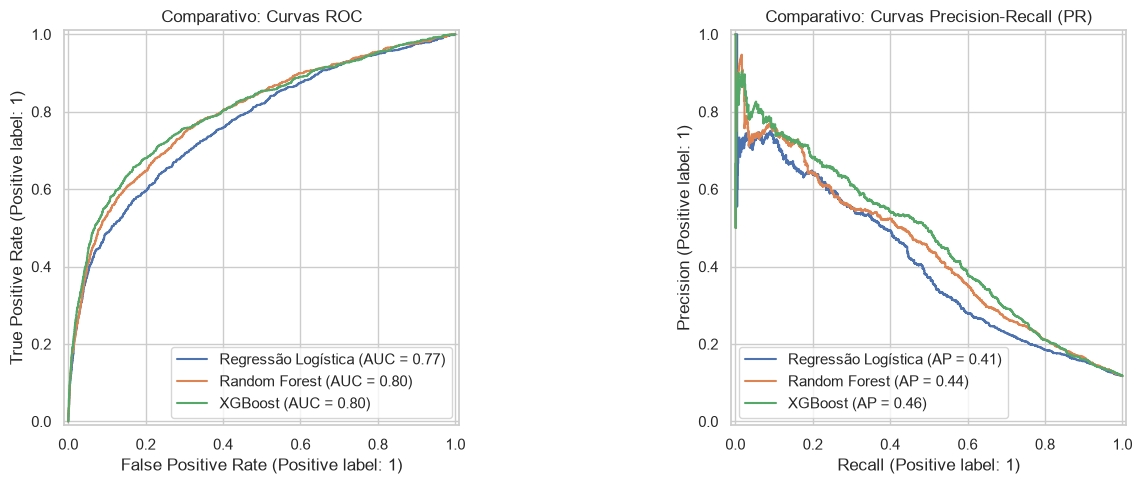

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nome, probas in modelos_probas.items():
    RocCurveDisplay.from_predictions(y_test, probas, name=nome, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probas, name=nome, ax=axes[1])

axes[0].set_title("Comparativo: Curvas ROC")
axes[1].set_title("Comparativo: Curvas Precision-Recall (PR)")
plt.tight_layout()
plt.show()

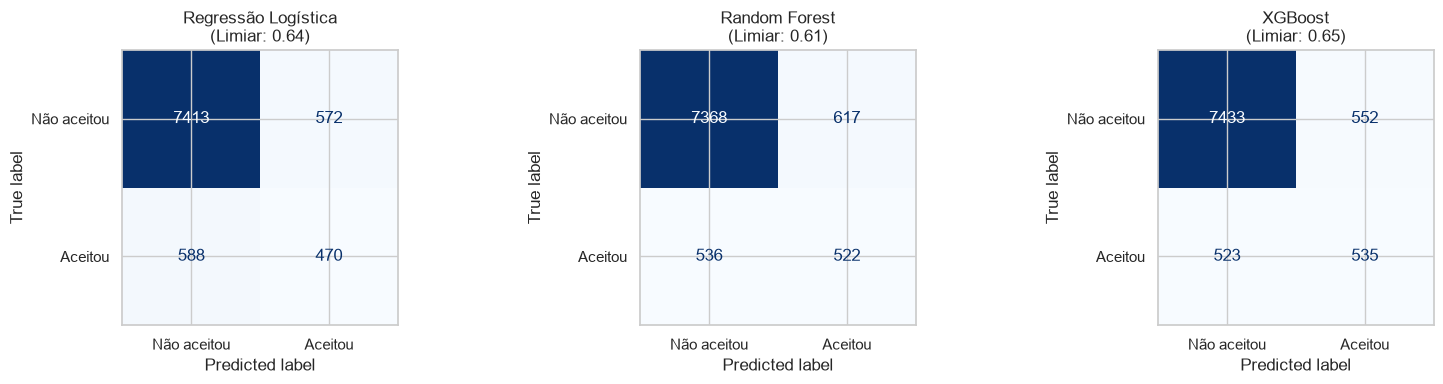

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes = axes.flatten()

for i, (nome, preds) in enumerate(modelos_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        preds,
        display_labels=["Não aceitou", "Aceitou"],
        values_format="d",
        ax=axes[i],
        colorbar=False,
        cmap="Blues"
    )
    axes[i].set_title(f"{nome}\n(Limiar: {limiares_otimos[nome]:.2f})")

plt.tight_layout()
plt.show()

C:\Users\yumi_\AppData\Local\Temp\ipykernel_12008\1150359792.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_lr_imp.head(7), x="Odds Ratio", y="Feature", ax=axes[0], palette="Greens_r")
C:\Users\yumi_\AppData\Local\Temp\ipykernel_12008\1150359792.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_xgb_imp.head(7), x="Importância", y="Feature", ax=axes[1], palette="Blues_r")


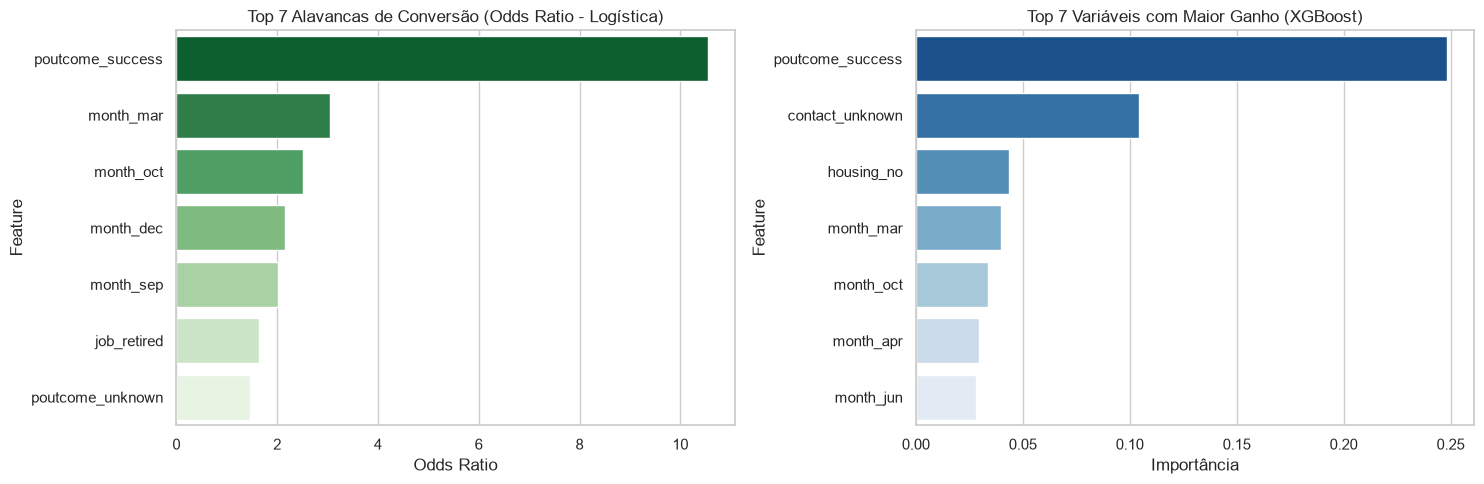

In [29]:
# 1. Odds Ratios da Regressão Logística
lr_model = pipelines["Regressão Logística"]
feature_names_lr = lr_model.named_steps["preprocessamento"].get_feature_names_out()
coef_lr = lr_model.named_steps["classificador"].coef_[0]
df_lr_imp = pd.DataFrame({
    "Feature": [f.split("__")[-1] for f in feature_names_lr],
    "Odds Ratio": np.exp(coef_lr)
}).sort_values(by="Odds Ratio", ascending=False)

# 2. Ganho Relativo no XGBoost
xgb_model = pipelines["XGBoost"]
feature_names_xgb = xgb_model.named_steps["preprocessamento"].get_feature_names_out()
imp_xgb = xgb_model.named_steps["classificador"].feature_importances_
df_xgb_imp = pd.DataFrame({
    "Feature": [f.split("__")[-1] for f in feature_names_xgb],
    "Importância": imp_xgb
}).sort_values(by="Importância", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_lr_imp.head(7), x="Odds Ratio", y="Feature", ax=axes[0], palette="Greens_r")
axes[0].set_title("Top 7 Alavancas de Conversão (Odds Ratio - Logística)")

sns.barplot(data=df_xgb_imp.head(7), x="Importância", y="Feature", ax=axes[1], palette="Blues_r")
axes[1].set_title("Top 7 Variáveis com Maior Ganho (XGBoost)")

plt.tight_layout()
plt.show()

In [30]:
REPORTS_DIR = ROOT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Identifica o melhor modelo com base em PR-AUC
melhor_modelo_nome = df_benchmark.iloc[0]["Modelo"]
melhor_pipe = pipelines[melhor_modelo_nome]
melhores_probas = modelos_probas[melhor_modelo_nome]

# 2. Exporta o resumo comparativo em JSON
caminho_metricas = REPORTS_DIR / "model_metrics.json"
dados_metricas = {
    "benchmark": df_benchmark.to_dict(orient="records"),
    "melhor_modelo": melhor_modelo_nome,
    "total_treino": int(len(X_train)),
    "total_teste": int(len(X_test)),
    "taxa_base_teste": float(taxa_teste)
}

with caminho_metricas.open("w", encoding="utf-8") as f:
    json.dump(dados_metricas, f, ensure_ascii=False, indent=4)

# 3. Exporta pontuações do melhor modelo
df_scores = pd.DataFrame({
    "test_row_rank": np.arange(1, len(X_test) + 1),
    "y_real": y_test.to_numpy(),
    "probabilidade": melhores_probas
}).sort_values(by="probabilidade", ascending=False).reset_index(drop=True)

caminho_scores = REPORTS_DIR / "test_propensity_scores.csv"
df_scores.to_csv(caminho_scores, index=False)

print(f"Métricas salvas")
print(f"Scores do campeão ({melhor_modelo_nome}) salvos")

Métricas salvas
Scores do campeão (XGBoost) salvos
